# 07 Retention drivers

**Question:** which early customer behaviours go with still buying 6 to 12 months later?

Notebook 05 measured retention (how many customers come back). This notebook looks at what is
associated with coming back, so retention effort can be aimed somewhere specific.

**Definitions**

- **Cohort:** identified customers whose first purchase was at least 365 days before the last date in
  the data, so every customer has a full year of history after their first order.
- **Retained:** made at least one purchase between day 181 and day 365 after their first order.
- **Early repeat:** made another purchase on a later calendar day within 30 days of the first order.
  Same-day invoices are not counted, because a second invoice on the same day is usually part of the
  same shopping visit.

The outcome window (day 181 to 365) starts well after the early-repeat window (day 1 to 30), so the
two do not overlap.

**Limits:** this is observational data. The results show which behaviours go with retention, not what
causes it. Customers who come back quickly may simply be more engaged to begin with.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency

DATA = Path("../data/processed/retail_transactions_clean.csv.gz")
OUT = Path("../data/processed/analytics")
SHOTS = Path("../screenshots")

tx = pd.read_csv(DATA, parse_dates=["invoice_date"], low_memory=False)
print(f"Rows loaded: {len(tx):,}")
print(tx["transaction_type"].value_counts(dropna=False).to_string())

Rows loaded: 1,033,036
transaction_type
Sale                      1007913
Cancellation                19104
Stock Adjustment             3393
Zero-Price Transaction       2621
Accounting Adjustment           5


## 1. One row per order

In [2]:
known = tx[tx["customer_id"].notna()].copy()
known["customer_id"] = known["customer_id"].astype("int64")

sales = known[
    (known["transaction_type"] == "Sale")
    & (known["line_category"] == "Merchandise")
    & (known["analysis_eligible"] == True)
]
cancels = known[known["transaction_type"].str.contains("cancel", case=False, na=False)]

orders = (
    sales.groupby(["customer_id", "invoice_no"])
    .agg(order_date=("invoice_date", "min"),
         order_value=("line_value", "sum"),
         products=("stock_code", "nunique"),
         country=("country", "first"))
    .reset_index()
    .sort_values(["customer_id", "order_date"])
)
data_end = known["invoice_date"].max()
print(f"Merchandise sale orders from identified customers: {len(orders):,}")
print(f"Customers: {orders['customer_id'].nunique():,}")
print(f"Last date in the data: {data_end:%Y-%m-%d}")

Merchandise sale orders from identified customers: 36,593
Customers: 5,852
Last date in the data: 2011-12-09


## 2. First order, early behaviour and the outcome for each customer

In [3]:
first = orders.groupby("customer_id").first().rename(columns={
    "order_date": "first_date", "order_value": "first_value",
    "products": "first_products", "country": "first_country"})
first = first.drop(columns="invoice_no")

o = orders.merge(first[["first_date"]], left_on="customer_id", right_index=True)
o["day"] = (o["order_date"].dt.normalize() - o["first_date"].dt.normalize()).dt.days

early = o[(o["day"] >= 1) & (o["day"] <= 30)].groupby("customer_id").size()
later = o[(o["day"] >= 181) & (o["day"] <= 365)].groupby("customer_id").size()

c = cancels.merge(first[["first_date"]], left_on="customer_id", right_index=True)
c["day"] = (c["invoice_date"].dt.normalize() - c["first_date"].dt.normalize()).dt.days
early_cancel = c[(c["day"] >= 0) & (c["day"] <= 30)].groupby("customer_id").size()

cust = first.copy()
cust["early_repeat"] = cust.index.isin(early.index).astype(int)
cust["retained"] = cust.index.isin(later.index).astype(int)
cust["early_cancel"] = cust.index.isin(early_cancel.index).astype(int)
cust["uk"] = (cust["first_country"] == "United Kingdom").astype(int)
cust["holiday_start"] = cust["first_date"].dt.month.isin([11, 12]).astype(int)

eligible = cust[cust["first_date"] <= data_end - pd.Timedelta(days=365)].copy()
eligible = eligible[eligible["first_value"] > 0]
print(f"Customers with a full year after their first order: {len(eligible):,}")
print(f"Overall retention (bought again in days 181-365): {eligible['retained'].mean():.2%}")

Customers with a full year after their first order: 4,284
Overall retention (bought again in days 181-365): 56.23%


## 3. Retention by group, with 95% confidence intervals and a chi-square test

In [4]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

eligible["first_value_band"] = pd.qcut(eligible["first_value"], 4,
                                       labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
eligible["first_products_band"] = pd.qcut(eligible["first_products"].rank(method="first"), 4,
                                          labels=["Q1 (fewest)", "Q2", "Q3", "Q4 (most)"])

drivers = {
    "early_repeat": "Bought again within 30 days",
    "first_value_band": "First order value (quartile)",
    "first_products_band": "Products in first order (quartile)",
    "uk": "UK customer",
    "holiday_start": "First order in Nov or Dec",
    "early_cancel": "Cancellation within 30 days",
}

rows = []
for col, label in drivers.items():
    table = pd.crosstab(eligible[col], eligible["retained"])
    chi2, p, dof, _ = chi2_contingency(table)
    for level, grp in eligible.groupby(col, observed=True):
        n, k = len(grp), int(grp["retained"].sum())
        lo, hi = wilson(k, n)
        rows.append({"driver": label, "group": str(level), "customers": n,
                     "retained": k, "retention_rate": k / n,
                     "ci_low": lo, "ci_high": hi, "chi2_p_value": p})

summary = pd.DataFrame(rows)
summary.to_csv(OUT / "retention_drivers_summary.csv", index=False)
pd.set_option("display.float_format", "{:.4f}".format)
summary

,driver,group,customers,retained,retention_rate,ci_low,ci_high,chi2_p_value
0,Bought again within 30 days,0,3472,1803,0.5193,0.5027,0.5359,0.0000
1,Bought again within 30 days,1,812,606,0.7463,0.7153,0.7750,0.0000
2,First order value (quartile),Q1 (lowest),1071,474,0.4426,0.4131,0.4725,0.0000
3,First order value (quartile),Q2,1071,598,0.5584,0.5285,0.5878,0.0000
4,First order value (quartile),Q3,1071,634,0.5920,0.5623,0.6210,0.0000
5,First order value (quartile),Q4 (highest),1071,703,0.6564,0.6274,0.6842,0.0000
6,Products in first order (quartile),Q1 (fewest),1071,551,0.5145,0.4845,0.5443,0.0000
7,Products in first order (quartile),Q2,1071,581,0.5425,0.5125,0.5721,0.0000
8,Products in first order (quartile),Q3,1071,623,0.5817,0.5519,0.6109,0.0000
9,Products in first order (quartile),Q4 (most),1071,654,0.6106,0.5811,0.6394,0.0000


## 4. Logistic regression: each driver while holding the others constant

The odds ratio says how the odds of being retained change for that driver, with the other drivers
held constant. Above 1 means higher odds of retention, below 1 means lower. First order value is
log-transformed because a few very large orders would otherwise dominate.

In [5]:
eligible["log_first_value"] = np.log(eligible["first_value"])
eligible["log_first_products"] = np.log(eligible["first_products"])

model = smf.logit(
    "retained ~ early_repeat + log_first_value + log_first_products + uk + holiday_start + early_cancel",
    data=eligible,
).fit(disp=False)

ci = model.conf_int()
logit = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_low": np.exp(ci[0]),
    "ci_high": np.exp(ci[1]),
    "p_value": model.pvalues,
}).drop(index="Intercept")
logit.to_csv(OUT / "retention_drivers_logit.csv")
print(f"Customers in model: {int(model.nobs):,}   Pseudo R-squared: {model.prsquared:.3f}")
logit

Customers in model: 4,284   Pseudo R-squared: 0.055


,odds_ratio,ci_low,ci_high,p_value
early_repeat,2.3206,1.9445,2.7695,0.0000
log_first_value,1.3780,1.2563,1.5116,0.0000
log_first_products,1.0138,0.9405,1.0928,0.7207
uk,1.0157,0.8001,1.2892,0.8985
holiday_start,1.8768,1.6314,2.1591,0.0000
early_cancel,1.3945,1.1799,1.6481,0.0001


## 4b. Sensitivity check: customers already buying before the data starts

The data begins on 1 December 2009. A customer whose "first" purchase is in December 2009 may in fact
be a long-standing customer whose earlier orders are simply not in the data. Those customers would
look unusually loyal and would also all fall in the Nov/Dec group. This check removes them and
re-runs the comparison and the model.

In [6]:
dec09 = (eligible["first_date"] < "2010-01-01")
print(f"Customers with a first purchase in Dec 2009: {dec09.sum():,} "
      f"(retention {eligible.loc[dec09, 'retained'].mean():.2%})")
print(f"Everyone else: {(~dec09).sum():,} (retention {eligible.loc[~dec09, 'retained'].mean():.2%})")

sens = eligible[~dec09].copy()
for col in ["early_repeat", "holiday_start", "early_cancel"]:
    g = sens.groupby(col)["retained"].agg(["size", "mean"])
    p = chi2_contingency(pd.crosstab(sens[col], sens["retained"]))[1]
    print(f"{drivers[col]}: no {g.loc[0,'mean']:.2%} (n={g.loc[0,'size']:,}) vs "
          f"yes {g.loc[1,'mean']:.2%} (n={g.loc[1,'size']:,}), p = {p:.2g}")

model_s = smf.logit(
    "retained ~ early_repeat + log_first_value + log_first_products + uk + holiday_start + early_cancel",
    data=sens,
).fit(disp=False)
ci_s = model_s.conf_int()
logit_s = pd.DataFrame({
    "odds_ratio": np.exp(model_s.params),
    "ci_low": np.exp(ci_s[0]),
    "ci_high": np.exp(ci_s[1]),
    "p_value": model_s.pvalues,
}).drop(index="Intercept")
logit_s.to_csv(OUT / "retention_drivers_logit_excl_dec2009.csv")
print(f"Customers in model: {int(model_s.nobs):,}")
logit_s.round(3)

Customers with a first purchase in Dec 2009: 951 (retention 78.97%)
Everyone else: 3,333 (retention 49.74%)
Bought again within 30 days: no 46.43% (n=2,798) vs yes 67.10% (n=535), p = 2.9e-18
First order in Nov or Dec: no 51.11% (n=2,962) vs yes 38.81% (n=371), p = 1e-05
Cancellation within 30 days: no 47.47% (n=2,730) vs yes 60.03% (n=603), p = 3.1e-08
Customers in model: 3,333


,odds_ratio,ci_low,ci_high,p_value
early_repeat,2.2320,1.8280,2.7270,0.0000
log_first_value,1.3110,1.1810,1.4550,0.0000
log_first_products,1.0890,1.0000,1.1850,0.0500
uk,1.0080,0.7810,1.3000,0.9530
holiday_start,0.5700,0.4540,0.7160,0.0000
early_cancel,1.3640,1.1310,1.6440,0.0010


## 5. Chart

The chart uses the 3,333 customers from section 4b (December 2009 starters removed), the same group
as the findings.

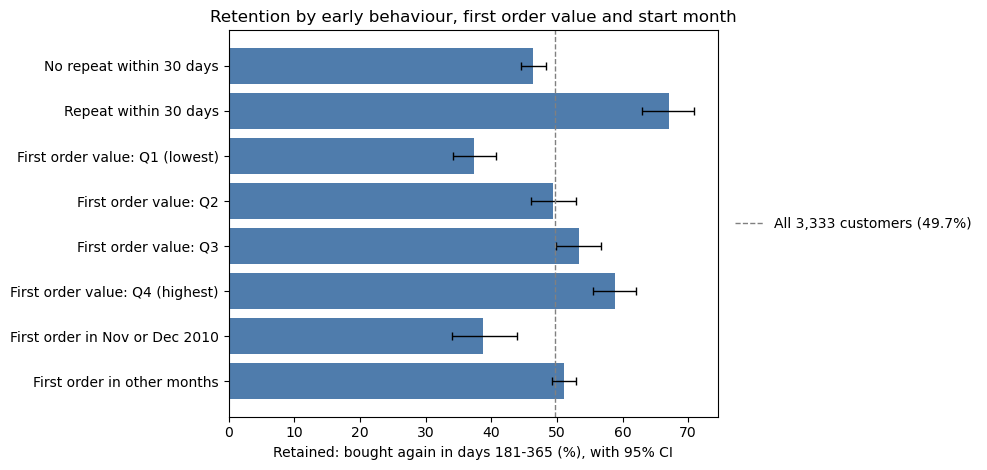

,label,customers,rate,lo,hi
0,No repeat within 30 days,2798,0.4643,0.4458,0.4828
1,Repeat within 30 days,535,0.6710,0.6301,0.7095
2,First order value: Q1 (lowest),834,0.3741,0.3419,0.4074
3,First order value: Q2,833,0.4946,0.4607,0.5285
4,First order value: Q3,833,0.5330,0.4991,0.5667
5,First order value: Q4 (highest),833,0.5882,0.5545,0.6212
6,First order in Nov or Dec 2010,371,0.3881,0.3399,0.4386
7,First order in other months,2962,0.5111,0.4931,0.5291


In [7]:
bars = []
for label, mask in [
    ("No repeat within 30 days", sens["early_repeat"] == 0),
    ("Repeat within 30 days", sens["early_repeat"] == 1),
]:
    bars.append((label, mask))
sens["first_value_band"] = pd.qcut(sens["first_value"], 4,
                                   labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
for q in ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]:
    bars.append((f"First order value: {q}", sens["first_value_band"] == q))
bars.append(("First order in Nov or Dec 2010", sens["holiday_start"] == 1))
bars.append(("First order in other months", sens["holiday_start"] == 0))

plot = []
for label, mask in bars:
    n, k = int(mask.sum()), int(sens.loc[mask, "retained"].sum())
    lo, hi = wilson(k, n)
    plot.append({"label": label, "customers": n, "rate": k / n, "lo": lo, "hi": hi})
plot = pd.DataFrame(plot)
plot.to_csv(OUT / "retention_drivers_chart_excl_dec2009.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(plot))
ax.barh(y, plot["rate"] * 100, color="#4f7cac")
ax.errorbar(plot["rate"] * 100, y,
            xerr=[(plot["rate"] - plot["lo"]) * 100, (plot["hi"] - plot["rate"]) * 100],
            fmt="none", ecolor="black", capsize=3, linewidth=1)
ax.axvline(sens["retained"].mean() * 100, color="grey", linestyle="--", linewidth=1,
           label=f"All {len(sens):,} customers ({sens['retained'].mean():.1%})")
ax.set_yticks(y, plot["label"])
ax.invert_yaxis()
ax.set_xlabel("Retained: bought again in days 181-365 (%), with 95% CI")
ax.set_title("Retention by early behaviour, first order value and start month")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
plt.tight_layout()
plt.savefig(SHOTS / "retention_drivers.png", dpi=150)
plt.show()
plot.round(4)

## 6. Key numbers for the write-up

In [8]:
er = summary[summary["driver"] == drivers["early_repeat"]].set_index("group")
fv = summary[summary["driver"] == drivers["first_value_band"]].set_index("group")
print(f"Eligible customers: {len(eligible):,}; overall retention {eligible['retained'].mean():.2%}")
print(f"Bought again within 30 days: {int(er.loc['1','customers']):,} customers, "
      f"retention {er.loc['1','retention_rate']:.2%} (95% CI {er.loc['1','ci_low']:.2%} to {er.loc['1','ci_high']:.2%})")
print(f"No repeat within 30 days:   {int(er.loc['0','customers']):,} customers, "
      f"retention {er.loc['0','retention_rate']:.2%} (95% CI {er.loc['0','ci_low']:.2%} to {er.loc['0','ci_high']:.2%})")
print(f"Chi-square p-value (early repeat): {er['chi2_p_value'].iloc[0]:.2g}")
print(f"First order value, lowest vs highest quartile: {fv.loc['Q1 (lowest)','retention_rate']:.2%} vs "
      f"{fv.loc['Q4 (highest)','retention_rate']:.2%}")
print()
print(logit.round(3).to_string())

Eligible customers: 4,284; overall retention 56.23%
Bought again within 30 days: 812 customers, retention 74.63% (95% CI 71.53% to 77.50%)
No repeat within 30 days:   3,472 customers, retention 51.93% (95% CI 50.27% to 53.59%)
Chi-square p-value (early repeat): 1.3e-31
First order value, lowest vs highest quartile: 44.26% vs 65.64%

                    odds_ratio  ci_low  ci_high  p_value
early_repeat            2.3210  1.9440   2.7700   0.0000
log_first_value         1.3780  1.2560   1.5120   0.0000
log_first_products      1.0140  0.9400   1.0930   0.7210
uk                      1.0160  0.8000   1.2890   0.8980
holiday_start           1.8770  1.6310   2.1590   0.0000
early_cancel            1.3940  1.1800   1.6480   0.0000


## Findings

**Data start check.** The data begins in December 2009, so 951 customers whose first recorded purchase
was that month are probably existing customers whose earlier orders are not in the data. They were
retained at 78.97%, against 49.74% for everyone else. They are excluded below, which leaves
**3,333 customers, 49.74% retained**. Before this check, a first purchase in November or December
looked like a sign of a loyal customer; after it, the result reverses.

On the 3,333 customers:

- **A second purchase within 30 days is the strongest signal.** 67.10% of these customers were
  retained, against 46.43% of the rest (p < 0.001). Holding the other factors constant, their odds of
  retention were 2.23 times higher (95% CI 1.83 to 2.73).
- **Larger first orders go with higher retention.** Doubling the value of the first order goes with
  about 21% higher odds of retention (odds ratio 1.31 per log unit, 95% CI 1.18 to 1.46).
- **Holiday first-timers return less.** Customers whose first purchase was in November or December
  2010 were retained at 38.81%, against 51.11% (odds ratio 0.57, 95% CI 0.45 to 0.72).
- **No difference** between UK and other customers (p = 0.95). The number of products in the first
  order has no clear effect once order value is held constant (p = 0.05).
- A cancellation within 30 days goes with higher retention (60.03% vs 47.47%). Customers who order
  more have more chances to cancel, so this most likely marks an active buyer and is not treated as a
  driver.

**What to do with it.** These are associations, not proof of cause: customers who come back quickly
may simply be more engaged. The next step is a test, not a rollout:

1. Send a follow-up offer to a random half of new customers within their first 30 days and compare
   retention at 6 to 12 months.
2. Treat holiday-season first-time buyers as their own group in that test, since they start from a
   lower base.